# ADP 28회 상황형 연습 - 풀이

**상황형 재구성 연습·예시 풀이이며 공식 원문/정답이 아닙니다.**

출처: 28회.pdf pp.2~3

원 자료 조건: 원 데이터가 첨부되지 않아 동일 컬럼·분석 주제의 합성 연습 자료를 제공합니다. 수치 정답은 원 시험과 다릅니다.

문제는 동봉 상황형 문제지와 같습니다. 원문은 문항목록.json·추가_문항명세.json에 보존합니다. 순서대로 실행하며 각 대문항에서 고정한 자료·전처리·분할을 후속 문항에 재사용합니다. 통계 답안은 선정 근거 → 가정·가설 → 통계량·p-value → 기각 여부·상황 해석 순서로 작성합니다. 확률·구간 추정·관리도 문항에 불필요한 귀무가설을 만들지 않습니다.

실행: 해당 회차 폴더에서 위에서 아래로 실행합니다. 가설검정_답안.json은 실제 계산한 가설·수치·결론 기록입니다.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display
# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/reconstruction.py').exists())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'기출문제/공통'))
from reconstruction import *
from matplotlib import font_manager
font_path=ROOT/'기출문제/공통/NanumGothic-Regular.ttf'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams['font.family']='NanumGothic';plt.rcParams['axes.unicode_minus']=False
HERE=ROOT/'기출문제'/'28회';DATA=HERE/'data';OUT=HERE/'실행결과';OUT.mkdir(exist_ok=True)
def load(name):return pd.read_csv(DATA/name)
print('데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님')

# 상황형 답안 기록 초기화
_SCENARIO_ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/scenario_inference.py').is_file())
sys.path.insert(0,str(_SCENARIO_ROOT/'기출문제/공통'))
from scenario_inference import (reset_reports, set_question, report_test, report_anova,
    report_correlations, report_adf, report_residuals, report_regression_diagnostics)
reset_reports(OUT)


데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 성적 범주 예측의 운영

학교는 여러 특성으로 성적 범주를 예측하려 한다. 기계학습 1~5단계는 동일 student 자료와 고정 학습·검증·시험 구간을 재사용한다.

자료: student.csv

### 1-1

연속·순서·명목·상수 특성과 클래스 분포를 탐색하고 학습·검증·시험을 나누시오. 분할 목적과 누출 위험을 설명하시오.

**판단 및 풀이 근거**

동일 상수는 정보가 없어 제거합니다. target 생성의 score가 연습용 강한 특성이므로 실제 후기 결과와 비교하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [2]:
set_question('1-1')
stu28=load('student.csv');print(stu28.describe(include='all'));print(stu28.target.value_counts());stu28=stu28.drop(columns=['constant'])
X28=stu28.drop(columns='target');y28=stu28.target;train28,test28=train_test_split(np.arange(len(y28)),test_size=.3,random_state=1234,stratify=y28)
fit28,valid28=train_test_split(train28,test_size=.25,random_state=1234,stratify=y28.iloc[train28])
print(len(fit28),len(valid28),len(test28))

               age     ordinal guardian constant       score      target
count   420.000000  420.000000      420      420  420.000000  420.000000
unique         NaN         NaN        3        1         NaN         NaN
top            NaN         NaN   mother        A         NaN         NaN
freq           NaN         NaN      149      420         NaN         NaN
mean     13.861905    2.421429      NaN      NaN    1.793527    1.814286
std       2.532835    1.144049      NaN      NaN    1.389622    1.098398
min      10.000000    1.000000      NaN      NaN   -1.873897    1.000000
25%      12.000000    1.000000      NaN      NaN    0.867009    1.000000
50%      14.000000    2.000000      NaN      NaN    1.669452    1.000000
75%      16.000000    3.000000      NaN      NaN    2.616214    2.000000
max      18.000000    4.000000      NaN      NaN    5.945004    5.000000
target
1    228
2    101
3     44
4     35
5     12
Name: count, dtype: int64
220 74 126


### 1-2

소수 등급 보완을 위해 복제 기반·근방 합성 기반 표본 증가를 학습 자료에만 적용하시오. 학습 적합 저차원 좌표로 전후를 비교하고 합성의 한계를 설명하시오.

**판단 및 풀이 근거**

후기는 SMOTE이나 명목 특성이 있어 SMOTENC로 보완했습니다. ordinal 또한 소수 합성될 수 있어 수치 좌표 가정의 한계를 명시합니다. test/validation에는 합성행을 넣지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

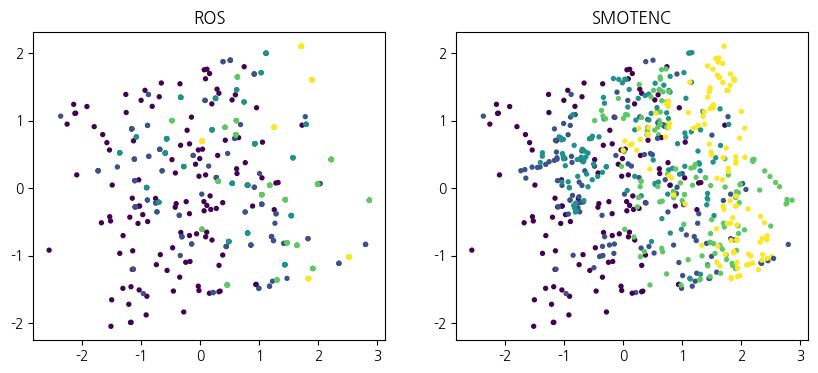

target
2    120
1    120
5    120
4    120
3    120
Name: count, dtype: int64 target
2    120
1    120
5    120
4    120
3    120
Name: count, dtype: int64


In [3]:
set_question('1-2')
from imblearn.over_sampling import RandomOverSampler,SMOTENC
from sklearn.decomposition import PCA
# 명목 guardian은 SMOTENC로 원 category를 보존. 일반 SMOTE로 원핫 중간값을 생성하지 않음.
num28=['age','score','ordinal'];sc28=StandardScaler().fit(X28.iloc[fit28][num28]);cat28=pd.Categorical(X28.guardian).codes
Z28=np.column_stack([sc28.transform(X28.iloc[fit28][num28]),cat28[fit28]])
small=int(y28.iloc[fit28].value_counts().min());neighbors=min(5,small-1);assert neighbors>=1
ros28=RandomOverSampler(random_state=1234);smote28=SMOTENC(categorical_features=[3],k_neighbors=neighbors,random_state=1234)
rosX,rosY=ros28.fit_resample(Z28,y28.iloc[fit28]);smX,smY=smote28.fit_resample(Z28,y28.iloc[fit28])
pca28=PCA(n_components=2,random_state=1234).fit(Z28)
fig,ax=plt.subplots(1,2,figsize=(10,4))
for a,xx,yy,title in [(ax[0],rosX,rosY,'ROS'),(ax[1],smX,smY,'SMOTENC')]:
    coords=pca28.transform(xx);a.scatter(coords[:,0],coords[:,1],c=yy,s=8);a.set_title(title)
plt.show();print(pd.Series(rosY).value_counts(),pd.Series(smY).value_counts())

### 1-3

신경망·배깅 트리·부스팅 트리 후보를 학습 내부 CV로 튜닝하시오. 같은 validation의 accuracy·학습 시간을 비교하고 탐색 범위와 측정 조건을 명시하시오.

**판단 및 풀이 근거**

신경망은 softmax 다중 분류를 지원하는 sklearn MLP로 구성해 보팅과 호환합니다. ROS/SMOTENC 비교는 앞 셀 학습 시각화이며 이 CV 실험은 원 학습 분포에서 수행한 별도 실험입니다. 리샘플링 모형 비교는 폴드 내부 imblearn Pipeline에 sampler를 넣어야 합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [4]:
set_question('1-3')
import time
from sklearn.neural_network import MLPClassifier
from src.MachineLearning.Optimization.grid_search import run_grid_search
from lightgbm import LGBMClassifier
models28={};table28=[]
for name,est,space in [('mlp',MLPClassifier(max_iter=350,random_state=1234),{'model__hidden_layer_sizes':[(16,),(32,)]}),('rf',RandomForestClassifier(n_estimators=50,random_state=1234),{'model__max_depth':[3,5]}),('lightgbm',LGBMClassifier(n_estimators=50,random_state=1234,verbosity=-1),{'model__num_leaves':[7,15]})]:
    begin=time.perf_counter();r=run_grid_search(X28.iloc[fit28],y28.iloc[fit28],tabular_pipeline(X28,est),overrides={'search_space':space,'cv':3})
    models28[name]=r.model;table28.append({'model':name,'CV_score':r.best_score,'validation_accuracy':accuracy_score(y28.iloc[valid28],r.model.predict(X28.iloc[valid28])),'fit_seconds':time.perf_counter()-begin})
comparison28=pd.DataFrame(table28);print(comparison28)

      model  CV_score  validation_accuracy  fit_seconds
0       mlp  0.595644             0.567568     0.544816
1        rf  0.572936             0.567568     0.325197
2  lightgbm  0.591324             0.472973     0.339237


/tmp/adp-update-py312/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (350) reached and the optimization hasn't converged yet.
  warnings.warn(
/tmp/adp-update-py312/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (350) reached and the optimization hasn't converged yet.
  warnings.warn(
/tmp/adp-update-py312/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (350) reached and the optimization hasn't converged yet.
  warnings.warn(
/tmp/adp-update-py312/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (350) reached and the optimization hasn't converged yet.
  warnings.warn(
/tmp/adp-update-py312/lib/python3.12/sit

### 1-4

세 분류기의 표결과 확률 결합을 validation에서 비교하시오. 선정 방식만 test에서 한 번 평가하고 결합의 성능 보장이 없는 이유를 설명하시오.

**판단 및 풀이 근거**

validation으로 보팅 선택 후 train+validation 재적합, test 단일 평가입니다. 확률 보정과 다수 클래스 우세에 주의합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [5]:
set_question('1-4')
from sklearn.ensemble import VotingClassifier
from sklearn.base import clone
votes28={};vote_rows=[]
for method in ['hard','soft']:
    vote=VotingClassifier([(name,clone(model)) for name,model in models28.items()],voting=method)
    vote.fit(X28.iloc[fit28],y28.iloc[fit28]);votes28[method]=vote;vote_rows.append({'voting':method,'validation_accuracy':accuracy_score(y28.iloc[valid28],vote.predict(X28.iloc[valid28]))})
vr=pd.DataFrame(vote_rows);print(vr);which=vr.loc[vr.validation_accuracy.idxmax(),'voting'];final_vote=clone(votes28[which]).fit(X28.iloc[train28],y28.iloc[train28]);final_pred=final_vote.predict(X28.iloc[test28]);print(which,{'test_accuracy':accuracy_score(y28.iloc[test28],final_pred),'test_macro_f1':f1_score(y28.iloc[test28],final_pred,average='macro')})

  voting  validation_accuracy
0   hard             0.540541
1   soft             0.540541
hard {'test_accuracy': 0.626984126984127, 'test_macro_f1': 0.4184195997239476}


/tmp/adp-update-py312/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (350) reached and the optimization hasn't converged yet.
  warnings.warn(
/tmp/adp-update-py312/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/tmp/adp-update-py312/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (350) reached and the optimization hasn't converged yet.
  warnings.warn(
/tmp/adp-update-py312/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/tmp/adp-update-py312/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWa

### 1-5

모형을 학교 시스템에 적용할 때 전처리 재사용·입력 검증·지연·재학습·롤백 기준을 설계하시오. 학생에 대한 판단을 모델 출력만으로 단정할 위험을 설명하시오.

**판단 및 풀이 근거**

데이터가 들어온다는 이유만으로 즉시 가중치를 갱신하지 않습니다. 검증·롤백 기준을 정합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [6]:
set_question('1-5')
print('전처리+모형 버전 및 클래스 순서 저장, 요청 스키마 검증, 추론 p95 지연 측정, 드리프트/클래스 recall 감시, 승인된 새 모델을 별도 평가 후 교체. 합성 학습 시간은 운영 지연의 대체 지표가 아님.')

전처리+모형 버전 및 클래스 순서 저장, 요청 스키마 검증, 추론 p95 지연 측정, 드리프트/클래스 recall 감시, 승인된 새 모델을 별도 평가 후 교체. 합성 학습 시간은 운영 지연의 대체 지표가 아님.


## 2. 관찰 기간과 사건 발생

36명의 time(1 이상)과 event(1:사건, 0:오른쪽 검열)가 주어졌다. 관측 종료를 사건으로 처리하지 않고 생존 확률을 추정하려 한다. 독립·비정보 검열을 가정한다.

자료: survival.csv

### 2-1

오른쪽 검열을 반영할 비모수 추정 방법을 선택하고 근거를 설명하시오. 시점별 위험집합·생존곡선·95% 신뢰구간을 제시하고 같은 시각의 사건·검열 처리와 추정의 한계를 설명하시오.

**판단 및 풀이 근거**

사건 직전 위험집합에서 사건만 분자로 계산합니다. 동일 시각 사건·검열 처리와 독립 검열 가정을 명시합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

    time  at_risk  events  censored  survival       low      high
0    2.0       36       2         0  0.944444  0.795657  0.985809
1    3.0       34       1         0  0.916667  0.763470  0.972337
2    6.0       33       1         0  0.888889  0.730519  0.956781
3    7.0       32       2         0  0.833333  0.666126  0.921439
4    8.0       30       2         3  0.777778  0.604443  0.882098
5    9.0       25       2         0  0.715556  0.534886  0.836078
6   10.0       23       2         0  0.653333  0.469579  0.786865
7   12.0       21       2         1  0.591111  0.407639  0.734896
8   13.0       18       1         1  0.558272  0.375460  0.706905
9   15.0       16       2         0  0.488488  0.308652  0.646204
10  16.0       14       1         0  0.453596  0.276952  0.614609
11  17.0       13       0         1  0.453596  0.276952  0.614609
12  19.0       12       5         0  0.264597  0.121462  0.432357
13  20.0        7       1         1  0.226798  0.095200  0.392178
14  21.0  

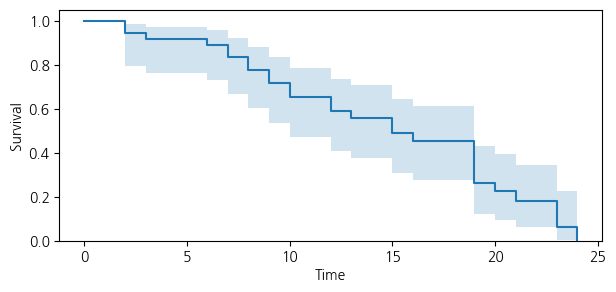

In [7]:
set_question('2-1')
surv=load('survival.csv');km=kaplan_meier(surv);km.to_csv(OUT/'kaplan_meier.csv',index=False);assert np.all(np.diff(km.survival)<=1e-12)

## 3. 두 학교의 성적 분포

학교 A 12명·B 24명의 독립 표본이다. 정규성을 가정하지 않고 두 학교의 성적 분포가 같은지 유의수준 5%에서 판단한다. 표본 수가 다르다는 사실만으로 대응 자료가 되지 않는다.

자료: school_scores.csv

### 3-1

두 독립 집단에 맞는 검정을 선택하시오. 정규성 탐색과 선택 근거, 귀무·대립가설·통계량·p-value·기각 여부를 제시하시오. 분포 형태가 다를 때 중앙값 차이로만 해석할 수 없는 이유를 설명하시오.

**판단 및 풀이 근거**

독립 두 집단이고 정규성을 가정하지 않아 Mann-Whitney U를 선택한다. H0: 두 학교 점수 분포 동일, H1: 다름. 서로 짝이 아니므로 signed-rank가 아니며 분포 형태가 다를 때 중앙값만의 검정이 아니다.

**계산·해석 상세**

같은 대상 전후의 signed-rank와 독립 두 학교 rank-sum은 다른 설계입니다. 작은 n만으로 비모수 검정이 자동 결정되지는 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

In [8]:
set_question('3-1')
school=load('school_scores.csv');a=school.loc[school.school=='A','score'];b_=school.loc[school.school=='B','score'];print(stats.shapiro(a),stats.shapiro(b_));print(stats.mannwhitneyu(a,b_,alternative='two-sided'))

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
_u=stats.mannwhitneyu(a,b_,alternative='two-sided')
report_test('Mann-Whitney U 양측','두 학교의 성적 분포가 같다','두 학교의 성적 분포가 다르다',_u.statistic,_u.pvalue,'두 학교의 성적 분포가 다르다','독립 관측·순위 비교·동률 고려. p값 계산 방식은 scipy auto이며 형태가 같아야 위치 차이 해석 가능.')

ShapiroResult(statistic=np.float64(0.8404851200698962), pvalue=np.float64(0.028066119063674105)) ShapiroResult(statistic=np.float64(0.9319643474865087), pvalue=np.float64(0.10786348502611526))
MannwhitneyuResult(statistic=np.float64(175.0), pvalue=np.float64(0.30606536398719364))
{
  "question": "3-1",
  "method": "Mann-Whitney U 양측",
  "H0": "두 학교의 성적 분포가 같다",
  "H1": "두 학교의 성적 분포가 다르다",
  "statistic": 175.0,
  "p_value": 0.30606536398719364,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "독립 관측·순위 비교·동률 고려. p값 계산 방식은 scipy auto이며 형태가 같아야 위치 차이 해석 가능.",
  "conclusion": "귀무가설을 기각하지 못한다. 두 학교의 성적 분포가 다르다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다."
}


## 4. 시식 전후 선호

동일 60명이 시식 전후에 선호(1)/비선호(0)를 답했다. 개인 간에는 독립이며 전후 응답은 짝지어져 있다. 선호 비율이 변했는지 유의수준 5%에서 판단한다.

자료: tasting.csv

### 4-1

전후 2×2 표를 구성하고 대응 구조에 맞는 검정을 선택하시오. 귀무·대립가설, 불일치 셀의 역할·정확 p-value·통계량·기각 여부와 시식 후 선호 변화의 결론을 제시하시오.

**판단 및 풀이 근거**

같은 사람의 이진 전후 반응은 대응 범주 자료다. McNemar 정확 검정에서 불일치 두 방향 확률의 같음을 평가한다. H0: p01=p10, H1: p01≠p10.

**계산·해석 상세**

같은 사람의 두 시점이므로 독립성 chi-square가 아닙니다. 불일치 셀 합이 작아도 exact 이항 검정을 적용합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

In [9]:
set_question('4-1')
from statsmodels.stats.contingency_tables import mcnemar
tasting=load('tasting.csv');table=pd.crosstab(tasting.before,tasting.after).reindex(index=[0,1],columns=[0,1],fill_value=0);print(table);result=mcnemar(table,exact=True);print({'statistic':result.statistic,'p_value':result.pvalue})

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_test('McNemar 정확 양측','p01=p10 (전후 주변 선호율 동일)','p01 != p10',result.statistic,result.pvalue,'시식 전후 선호 비율이 변했다','개인 간 독립·짝 유지·불일치 셀 합 조건부 정확 이항 검정. 독립성 카이제곱과 다름.')

after    0   1
before        
0       16  20
1       11  13
{'statistic': np.float64(11.0), 'p_value': np.float64(0.14961278438568115)}
{
  "question": "4-1",
  "method": "McNemar 정확 양측",
  "H0": "p01=p10 (전후 주변 선호율 동일)",
  "H1": "p01 != p10",
  "statistic": 11.0,
  "p_value": 0.14961278438568115,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "개인 간 독립·짝 유지·불일치 셀 합 조건부 정확 이항 검정. 독립성 카이제곱과 다름.",
  "conclusion": "귀무가설을 기각하지 못한다. 시식 전후 선호 비율이 변했다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다."
}


## 5. 공통 요인을 통제한 관계

독립 표본 100개의 연속 x·y·z가 있다. z의 선형 관계를 제거한 뒤 x와 y에 관계가 남는지 유의수준 5%에서 조사한다. 선형·정규 오차 모형을 작업 가정한다.

자료: partial.csv

### 5-1

공통 변수 z를 통제할 관계 평가 방법을 선택하시오. 단순 관계와 통제 후 관계의 크기, 귀무·대립가설·통계량·자유도·p-value·기각 여부를 제시하고 인과 해석의 한계를 설명하시오.

**판단 및 풀이 근거**

z에 선형 회귀한 두 잔차의 상관으로 편상관을 구한다. H0: ρxy.z=0, H1: ρxy.z≠0. 검정 자유도는 n-3이며 잔차의 단순 Pearson p값(n-2)을 재사용하지 않는다.

**계산·해석 상세**

잔차를 상관 분석하며 자유도 n-k-2(n-3)를 사용합니다. 잔차 pearsonr의 n-2 p값을 편상관 p값으로 그대로 사용하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

In [10]:
set_question('5-1')
partial=load('partial.csv');D=sm.add_constant(partial[['z']]);rx=sm.OLS(partial.x,D).fit().resid;ry=sm.OLS(partial.y,D).fit().resid;r=stats.pearsonr(rx,ry)[0];df_=len(partial)-3;t=r*np.sqrt(df_/(1-r*r));p=2*stats.t.sf(abs(t),df_);print({'simple_r':stats.pearsonr(partial.x,partial.y)[0],'partial_r':r,'df':df_,'t':t,'p':p})

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_test('1개 변수 보정 편상관 t','rho_xy.z=0','rho_xy.z != 0',t,p,'z를 선형 통제한 x와 y에 관계가 남는다','독립 표본·선형 정규 모형·보정변수 1개. 관측 관계이며 인과가 아님.',df=df_)

{'simple_r': np.float64(0.7443636058811574), 'partial_r': np.float64(-0.041062294370144733), 'df': 97, 't': np.float64(-0.40475807595633023), 'p': np.float64(0.6865465398111293)}
{
  "question": "5-1",
  "method": "1개 변수 보정 편상관 t",
  "H0": "rho_xy.z=0",
  "H1": "rho_xy.z != 0",
  "statistic": -0.40475807595633023,
  "p_value": 0.6865465398111293,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "독립 표본·선형 정규 모형·보정변수 1개. 관측 관계이며 인과가 아님.",
  "conclusion": "귀무가설을 기각하지 못한다. z를 선형 통제한 x와 y에 관계가 남는다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다.",
  "df": 97
}
